In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/city_day.csv")

print(df.shape)
print(df.columns.tolist())
print(df.head())
df.info()

(29531, 16)
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']
        City        Date  PM2.5  PM10     NO    NO2    NOx  NH3     CO    SO2  \
0  Ahmedabad  2015-01-01    NaN   NaN   0.92  18.22  17.15  NaN   0.92  27.64   
1  Ahmedabad  2015-01-02    NaN   NaN   0.97  15.69  16.46  NaN   0.97  24.55   
2  Ahmedabad  2015-01-03    NaN   NaN  17.40  19.30  29.70  NaN  17.40  29.07   
3  Ahmedabad  2015-01-04    NaN   NaN   1.70  18.48  17.97  NaN   1.70  18.59   
4  Ahmedabad  2015-01-05    NaN   NaN  22.10  21.42  37.76  NaN  22.10  39.33   

       O3  Benzene  Toluene  Xylene  AQI AQI_Bucket  
0  133.36     0.00     0.02    0.00  NaN        NaN  
1   34.06     3.68     5.50    3.77  NaN        NaN  
2   30.70     6.80    16.40    2.25  NaN        NaN  
3   36.08     4.43    10.14    1.00  NaN        NaN  
4   39.31     7.01    18.89    2.78  NaN        NaN  
<class 'pandas.DataFrame'>
RangeIndex: 29531

| Column | What I think it means |
|---|---|
| City | City where it was measured |
| Date | Day of the reading |
| PM2.5 | Tiny dust particles in the air up to 2.5 micrometres|
| PM10 | Bigger dust particles up to 10 micrometres |
| NO | Nitric oxide, a gas from vehicle and fuel burning |
| NO2 | Nitrogen dioxide, a gas from traffic and industry |
| NOx | Total of nitrogen oxides (NO + NO2 and related gases) |
| NH3 | Ammonia, mostly from farming and fertilizers |
| CO | Carbon monoxide, from incomplete burning of fuel |
| SO2 | Sulphur dioxide, from coal burning and industry |
| O3 |Ozone, formed near the ground when sunlight reacts with other pollutants |
| Benzene | A harmful chemical (VOC) from petrol and industry |
| Toluene | A VOC from paints, solvents and petrol |
| Xylene | A VOC from paints, solvents and petrol |
| AQI | Air Quality Index: one overall number (higher = worse air) |
| AQI_Bucket | AQI turned into a category: Good, Satisfactory, Moderate, Poor, Very Poor, Severe |

In [4]:
print(df.isnull().sum())

City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64


In [5]:
print(df["City"].nunique())
print(df["City"].value_counts())

26
City
Ahmedabad             2009
Bengaluru             2009
Chennai               2009
Delhi                 2009
Lucknow               2009
Mumbai                2009
Hyderabad             2006
Patna                 1858
Gurugram              1679
Visakhapatnam         1462
Amritsar              1221
Jorapokhar            1169
Jaipur                1114
Thiruvananthapuram    1112
Amaravati              951
Brajrajnagar           938
Talcher                925
Kolkata                814
Guwahati               502
Coimbatore             386
Shillong               310
Chandigarh             304
Bhopal                 289
Ernakulam              162
Kochi                  162
Aizawl                 113
Name: count, dtype: int64


In [6]:
# Convert Date from text to a real date type
df["Date"] = pd.to_datetime(df["Date"])

# Check that it worked
print(df["Date"].dtype)
print(df["Date"].min())
print(df["Date"].max())

datetime64[us]
2015-01-01 00:00:00
2020-07-01 00:00:00


In [7]:
# Extract parts of the date into new columns
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month

# Map each month to an Indian season
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Summer"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-Monsoon"

df["Season"] = df["Month"].apply(get_season)

# Check the result
print(df[["Date", "Year", "Month", "Season"]].head())
print(df["Season"].value_counts())

        Date  Year  Month  Season
0 2015-01-01  2015      1  Winter
1 2015-01-02  2015      1  Winter
2 2015-01-03  2015      1  Winter
3 2015-01-04  2015      1  Winter
4 2015-01-05  2015      1  Winter
Season
Monsoon         9355
Summer          8272
Winter          7440
Post-Monsoon    4464
Name: count, dtype: int64


In [8]:
# 1. Fully identical rows
print("Fully duplicated rows:", df.duplicated().sum())

# 2. Same city AND same date appearing more than once
print("Duplicate City+Date pairs:", df.duplicated(subset=["City", "Date"]).sum())

Fully duplicated rows: 0
Duplicate City+Date pairs: 0


NO DUPLICATES FOUND

In [9]:
# 1. Percentage of missing values per column
missing_percent = (df.isnull().mean() * 100).round(1)
print(missing_percent.sort_values(ascending=False))

# 2. Missing PM10 percentage for each city
pm10_missing_by_city = df.groupby("City")["PM10"].apply(lambda x: x.isnull().mean() * 100).round(1)
print(pm10_missing_by_city.sort_values(ascending=False))

Xylene        61.3
PM10          37.7
NH3           35.0
Toluene       27.2
Benzene       19.0
AQI_Bucket    15.9
AQI           15.9
PM2.5         15.6
NOx           14.2
O3            13.6
SO2           13.1
NO            12.1
NO2           12.1
CO             7.0
City           0.0
Date           0.0
Year           0.0
Month          0.0
Season         0.0
dtype: float64
City
Lucknow               100.0
Patna                  89.7
Chennai                85.0
Ahmedabad              79.7
Mumbai                 62.0
Gurugram               55.9
Jorapokhar             23.5
Shillong               22.3
Talcher                19.4
Brajrajnagar           18.4
Bengaluru              17.9
Hyderabad              17.7
Visakhapatnam          16.1
Kolkata                 6.8
Amaravati               5.8
Amritsar                5.2
Delhi                   3.8
Thiruvananthapuram      3.4
Bhopal                  3.1
Ernakulam               2.5
Coimbatore              1.8
Jaipur                  1.3
Aiz

In [10]:
# For each city, what % of each pollutant is missing?
pollutants = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"]

missing_by_city = df.groupby("City")[pollutants].apply(lambda g: g.isnull().mean() * 100).round(0)
print(missing_by_city)

                    PM2.5   PM10    NO   NO2    NOx    NH3    CO   SO2     O3  \
City                                                                            
Ahmedabad            31.0   80.0  30.0  30.0   30.0  100.0  30.0  32.0   34.0   
Aizawl                2.0    1.0   0.0   0.0    0.0    0.0   0.0   0.0    8.0   
Amaravati             6.0    6.0   6.0   6.0    6.0    6.0  10.0   7.0    6.0   
Amritsar             10.0    5.0   8.0   4.0   24.0    3.0   6.0  14.0    9.0   
Bengaluru             7.0   18.0   0.0   0.0    0.0   10.0   1.0   0.0    7.0   
Bhopal                3.0    3.0   3.0   3.0    3.0    3.0   3.0   3.0    3.0   
Brajrajnagar         20.0   18.0  26.0  25.0   19.0   24.0  16.0  21.0   22.0   
Chandigarh            5.0    0.0   1.0   1.0    1.0    3.0   0.0   0.0    0.0   
Chennai               6.0   85.0   2.0   2.0    2.0   23.0   1.0   2.0    2.0   
Coimbatore            2.0    2.0  14.0   3.0    1.0   32.0   1.0   1.0    1.0   
Delhi                 0.0   

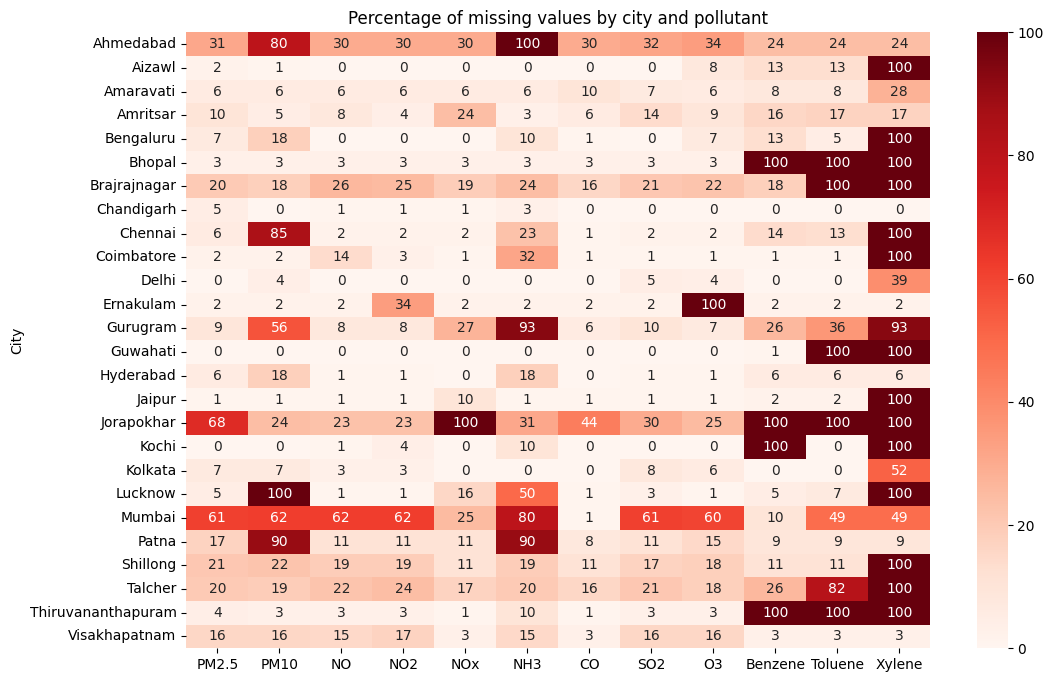

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
sns.heatmap(missing_by_city, annot=True, fmt=".0f", cmap="Reds")
plt.title("Percentage of missing values by city and pollutant")
plt.show()

In [12]:
# 1. Make a copy so the original stays safe
df_clean = df.copy()

# 2. Drop Xylene (too much missing)
df_clean = df_clean.drop(columns=["Xylene"])

# 3. Sort so each city's days are in order
df_clean = df_clean.sort_values(["City", "Date"])

# 4. Fill small gaps using the same city's neighbouring days
fill_cols = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene"]
df_clean[fill_cols] = df_clean.groupby("City")[fill_cols].transform(
    lambda s: s.interpolate(limit=3)
)

# 5. Check how much is still missing
print((df_clean.isnull().mean() * 100).round(1).sort_values(ascending=False))

PM10          35.9
NH3           33.2
Toluene       25.3
Benzene       16.9
AQI_Bucket    15.9
AQI           15.9
PM2.5         13.8
NOx           12.8
O3            11.2
SO2           10.7
NO            10.1
NO2           10.1
CO             4.9
City           0.0
Date           0.0
Year           0.0
Month          0.0
Season         0.0
dtype: float64


In [13]:
# 1. Summary statistics for the numeric columns
pollutant_cols = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene", "AQI"]
print(df_clean[pollutant_cols].describe().round(1))

# 2. Count impossible values (negative concentrations)
print("Negative values per column:")
print((df_clean[pollutant_cols] < 0).sum())

         PM2.5     PM10       NO      NO2      NOx      NH3       CO      SO2  \
count  25441.0  18919.0  26551.0  26547.0  25738.0  19719.0  28079.0  26362.0   
mean      67.4    118.2     17.6     28.3     32.3     23.4      2.2     14.8   
std       65.2     91.1     23.1     24.4     31.7     25.6      6.9     18.8   
min        0.0      0.0      0.0      0.0      0.0      0.0      0.0      0.0   
25%       28.7     56.1      5.6     11.6     12.8      8.4      0.5      5.7   
50%       48.4     95.6      9.9     21.4     23.4     15.7      0.9      9.2   
75%       80.5    149.9     20.0     37.4     40.0     30.0      1.4     15.4   
max      950.0   1000.0    390.7    362.2    467.6    352.9    175.8    193.9   

            O3  Benzene  Toluene      AQI  
count  26220.0  24545.0  22058.0  24850.0  
mean      34.3      3.4      8.7    166.5  
std       21.7     16.5     20.0    140.7  
min        0.0      0.0      0.0     13.0  
25%       18.7      0.1      0.6     81.0  
50%   

In [14]:
# 1. How many rows have AQI above 500 (above the official scale)?
print("AQI above 500:", (df_clean["AQI"] > 500).sum())

# 2. Which cities and dates are these?
print(df_clean[df_clean["AQI"] > 500][["City", "Date", "PM2.5", "PM10", "AQI"]].head(15))

# 3. The 5 highest PM2.5 readings with their city and date
print(df_clean.nlargest(5, "PM2.5")[["City", "Date", "PM2.5", "AQI"]])

AQI above 500: 543
         City       Date   PM2.5  PM10     AQI
30  Ahmedabad 2015-01-31   94.52   NaN   514.0
31  Ahmedabad 2015-02-01  135.99   NaN   782.0
32  Ahmedabad 2015-02-02  178.33   NaN   914.0
33  Ahmedabad 2015-02-03  139.70   NaN   660.0
43  Ahmedabad 2015-02-13  103.36   NaN   510.0
44  Ahmedabad 2015-02-14  177.33   NaN   761.0
46  Ahmedabad 2015-02-16   99.70   NaN   536.0
48  Ahmedabad 2015-02-18  100.79   NaN   592.0
50  Ahmedabad 2015-02-20  140.29   NaN   588.0
51  Ahmedabad 2015-02-21  239.96   NaN  1141.0
52  Ahmedabad 2015-02-22  142.96   NaN   669.0
53  Ahmedabad 2015-02-23  238.41   NaN  1247.0
63  Ahmedabad 2015-03-05  173.01   NaN   780.0
77  Ahmedabad 2015-03-19  105.06   NaN   883.0
78  Ahmedabad 2015-03-20   94.10   NaN   720.0
           City       Date   PM2.5    AQI
13041  Gurugram 2017-08-29  949.99    NaN
25729  Shillong 2019-09-03  917.77    NaN
14156  Guwahati 2019-05-04  916.67    NaN
12504  Gurugram 2016-03-10  914.94  676.0
25728  Shillong 201

In [15]:
print(df_clean[df_clean["AQI"] > 500]["City"].value_counts())

City
Ahmedabad     412
Delhi          48
Patna          25
Gurugram       22
Lucknow        15
Jorapokhar      7
Amritsar        4
Hyderabad       4
Talcher         4
Guwahati        2
Name: count, dtype: int64


In [16]:
# 1. Look at Ahmedabad's NO, CO and AQI side by side
print(df_clean[df_clean["City"] == "Ahmedabad"][["Date", "NO", "CO", "AQI"]].head(10))

# 2. For each city, what fraction of rows have NO exactly equal to CO?
same_no_co = (df_clean["NO"] == df_clean["CO"]).groupby(df_clean["City"]).mean().round(2)
print(same_no_co.sort_values(ascending=False))

        Date       NO       CO  AQI
0 2015-01-01    0.920    0.920  NaN
1 2015-01-02    0.970    0.970  NaN
2 2015-01-03   17.400   17.400  NaN
3 2015-01-04    1.700    1.700  NaN
4 2015-01-05   22.100   22.100  NaN
5 2015-01-06   45.410   45.410  NaN
6 2015-01-07  112.160  112.160  NaN
7 2015-01-08   80.870   80.870  NaN
8 2015-01-09   29.160   29.160  NaN
9 2015-01-10   80.615   80.615  NaN
City
Ahmedabad             0.67
Aizawl                0.00
Amaravati             0.00
Amritsar              0.00
Bengaluru             0.00
Bhopal                0.00
Brajrajnagar          0.00
Chandigarh            0.00
Chennai               0.00
Coimbatore            0.00
Delhi                 0.00
Ernakulam             0.00
Gurugram              0.00
Guwahati              0.00
Hyderabad             0.00
Jaipur                0.00
Jorapokhar            0.00
Kochi                 0.00
Kolkata               0.00
Lucknow               0.00
Mumbai                0.00
Patna                 0.00
Shill

In [17]:
# Find the suspicious rows: Ahmedabad where NO equals CO
bad_rows = (df_clean["City"] == "Ahmedabad") & (df_clean["NO"] == df_clean["CO"])
print("Suspicious rows:", bad_rows.sum())

# Set CO and AQI to missing for those rows
df_clean.loc[bad_rows, ["CO", "AQI", "AQI_Bucket"]] = np.nan

# Check: how many AQI values are still above 500?
print("AQI above 500 now:", (df_clean["AQI"] > 500).sum())

Suspicious rows: 1346
AQI above 500 now: 131


In [18]:
print(df_clean[df_clean["AQI"] > 500]["City"].value_counts())

City
Delhi         48
Patna         25
Gurugram      22
Lucknow       15
Jorapokhar     7
Amritsar       4
Hyderabad      4
Talcher        4
Guwahati       2
Name: count, dtype: int64


In [19]:
# 1. Flag rows where AQI is above the official 500 scale
df_clean["AQI_Above_500"] = df_clean["AQI"] > 500

# 2. Final check of the cleaned data
print(df_clean.shape)
print(df_clean.isnull().sum())

# 3. Save the cleaned data to a new file
df_clean.to_csv("../data/city_day_clean.csv", index=False)
print("Saved!")

(29531, 19)
City                 0
Date                 0
PM2.5             4090
PM10             10612
NO                2980
NO2               2984
NOx               3793
NH3               9812
CO                2798
SO2               3169
O3                3311
Benzene           4986
Toluene           7473
AQI               5929
AQI_Bucket        5929
Year                 0
Month                0
Season               0
AQI_Above_500        0
dtype: int64
Saved!


## Data Cleaning Summary

| Issue | Finding | Action |
|---|---|---|
| Date stored as text | `Date` was a string | Converted to datetime |
| New time features | Needed for trend and season analysis | Added Year, Month, Season |
| Duplicates | 0 duplicate rows, 0 duplicate City+Date pairs | None needed |
| Xylene | 61% missing, 100% missing in ~12 cities | Dropped |
| Short gaps | Gaps in pollutant columns | Filled using the same city's neighbouring days (max 3 days) |
| Long gaps | Some cities never measured some pollutants | Left as missing |
| Negative values | 0 found | None needed |
| Ahmedabad CO | CO identical to NO in 1,346 rows (hypothesis: copy error) | Set CO, AQI, AQI_Bucket to missing for those rows |
| AQI above 500 | 131 rows remain, mostly Delhi, Patna, Gurugram, Lucknow | Kept, flagged in `AQI_Above_500` |